In [77]:
import numpy as np
import matplotlib.pyplot as plt

# Hydrogen-like atoms: radial Schrödinger equation solved with Verlet 

We work in **atomic units** ($\hbar = m_e = e = 4\pi\varepsilon_0 = 1$). For a single electron in the Coulomb field of a nucleus of charge $Z$, the potential is

$$
V(r) = -\frac{Z}{r}.
$$

($Z=1$ is hydrogen, $Z=2$ is He$^+$, and so on.) The exact bound-state energies are

$$
E_n = -\frac{Z^2}{2n^2}, \qquad n = 1, 2, 3, \dots
$$

and they depend only on the principal quantum number $n$, not on the angular momentum $\ell$ ($\ell = 0, \dots, n-1$). The goal of this notebook is to recover this spectrum **numerically**, without using the analytic solution.

From 3D to a 1D radial equation

Since $V$ is central, we separate variables:

$$
\psi_{n\ell m}(\mathbf r) = \frac{u_{n\ell}(r)}{r}\, Y_{\ell m}(\theta, \phi).
$$

The radial function $u(r) = r R(r)$ obeys a one-dimensional Schrödinger equation:

$$
-\frac{1}{2}\,u''(r) + \left[ V(r) + \frac{\ell(\ell+1)}{2r^2} \right] u(r) = E\, u(r).
$$

The term $\frac{\ell(\ell+1)}{2r^2}$ is the **centrifugal barrier**.

**Boundary conditions** for a bound state:

- $u(0) = 0$, so that $\psi$ is regular at the origin. Near $r = 0$ the regular solution behaves as $u \sim r^{\ell+1}$, the irregular one as $u \sim r^{-\ell}$.
- $u(r) \to 0$ for $r \to \infty$ (normalisable state). 

In [78]:
n_points = int(1e5)
length = 100
zeroth_point = 0.01

Z = 1  # Atomic number (for hydrogen, Z=1)

## Why Verlet?

Rearranging the radial equation gives

$$
u''(r) = f(r)\, u(r), \qquad f(r) = 2\left[ V(r) - E \right] + \frac{\ell(\ell+1)}{r^2}.
$$

This is formally the same as Newton's equation $\ddot q = F(q)$ with $r$ playing the role of time. The **Verlet** (Störmer) scheme replaces the second derivative with the symmetric three-point stencil

$$
u''(r_i) \approx \frac{u_{i+1} - 2u_i + u_{i-1}}{h^2},
$$

and we obtain the recursion

$$
u_{i-1} = 2u_i - u_{i+1} + h^2 f(r_i)\, u_i .
$$

Properties:

- **Second-order accurate**: the local error is $O(h^4)$, the global error $O(h^2)$.
- **Time-reversible**: the same formula can be iterated forward or backward. Here we use it **backward**, from large $r$ towards the origin.
- It needs two starting values, not a value and a derivative.

In [79]:
def v(r):
    return -1.0 / r

def solve_verlet(length, zeroth_point, n_points, l, e, Z=1):
    r = np.linspace(zeroth_point, length, n_points)
    h = r[1] - r[0]                      # step size
    u = np.zeros(n_points)
    u[-1] = 0.0                          # u(r_max) = 0
    u[-2] = 1e-5                      # guess iniziale per u(r_max - h)
    for i in range(n_points - 2, 0, -1): # i = n-2, ..., 1 
        f = 2 * (Z*v(r[i]) - e) + l * (l + 1) / r[i]**2
        u[i - 1] = 2 * u[i] - u[i + 1] + h**2 * f * u[i]
    return r, u

def count_nodes(u):
    return int( np.sum(u[:-1] * u[1:] < 0))


## Shooting method

The recursion alone cannot fix $E$. We need a criterion to tell whether a trial energy is too low or too high. The algorithm is:

1. Choose a trial energy $E$.
2. **Integrate inward** from $r_{\max}$ ($u_{N} = 0$, $u_{N-1} = \varepsilon$ with $\varepsilon$ small and arbitrary) down to $r_0$. This fixes the correct decay at infinity.
3. **Count the nodes** (sign changes) of the resulting $u(r)$.
4. Use the node count to update $E$ by **bisection**.

### Why nodes?

The eigenfunction $u_{n\ell}$ has exactly $n - \ell - 1$ radial nodes. The number of nodes of the inward solution increases monotonically with $E$:

- if $E$ is too low, the solution has **at most** $n - \ell - 1$ nodes: raise the lower bound $E_{\min}$;
- if $E$ is too high, it has **more than** $n - \ell - 1$ nodes: lower the upper bound $E_{\max}$.

Bisection then converges to the lowest energy at which the extra node appears, which is exactly $E_n$.

In [80]:
energies = []
cond = True
tollerance = 1e-6
for n in range(1, 5):  # n = 1, 2, 3, 4
    for l in range(n):  # l = 0, 1, ..., n-1
        cond = True
        e_min = -10
        e_max = 0
        while cond:
            e = (e_min + e_max) / 2
            solve = solve_verlet(length, zeroth_point, n_points, l, e, Z)
            r, u = solve
            nodes = count_nodes(u)
            if nodes > n-l-1:
                e_max = e
            else:
                e_min = e
            if abs(e_max - e_min) < tollerance:
                cond = False
                energies.append(e)
                print(f"Found energy for n={n}, l={l}: E = {e:.6f} Hartree")

Found energy for n=1, l=0: E = -0.482107 Hartree
Found energy for n=2, l=0: E = -0.122730 Hartree
Found energy for n=2, l=1: E = -0.125000 Hartree
Found energy for n=3, l=0: E = -0.054880 Hartree
Found energy for n=3, l=1: E = -0.055556 Hartree
Found energy for n=3, l=2: E = -0.055556 Hartree
Found energy for n=4, l=0: E = -0.030964 Hartree
Found energy for n=4, l=1: E = -0.031250 Hartree
Found energy for n=4, l=2: E = -0.031250 Hartree
Found energy for n=4, l=3: E = -0.031250 Hartree


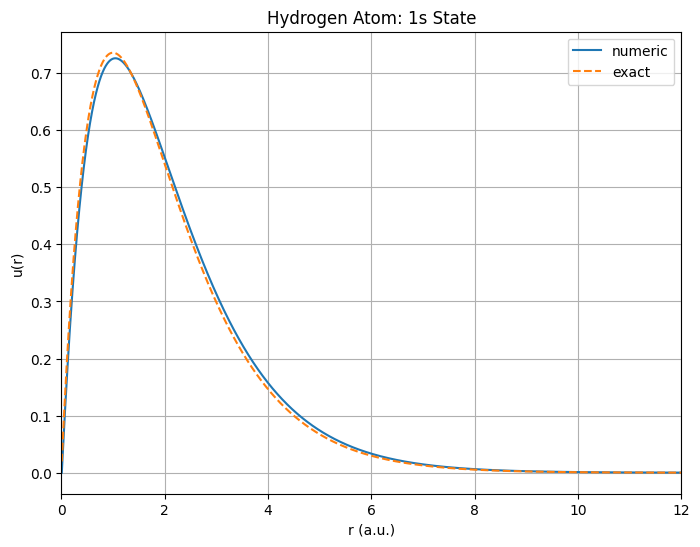

In [81]:
r, u = solve_verlet(length, zeroth_point, n_points, 0, energies[0], Z)  # 1s
u = u / np.sqrt(np.trapezoid(u**2, r))     
u *= np.sign(u[np.argmax(np.abs(u))]) 
plt.figure(figsize=(8, 6))
plt.title("Hydrogen Atom: 1s State")
plt.xlabel("r (a.u.)")
plt.ylabel("u(r)") 
plt.grid()
plt.plot(r, u, label="numeric")
plt.plot(r, 2*r*np.exp(-r), "--", label="exact")
plt.xlim(0, 12); plt.legend(); plt.show()